In [1]:
import sys

sys.path.append("..")

from sklearn.metrics import mean_squared_error, r2_score
from classes.feature import PCAFeatureReducer, WPTFeatureExtractor, RMSFeatureExtractor
from classes.loader.loader import Loader
import numpy as np
import matplotlib.pyplot as plt
from training.utils import get_filename

In [263]:
PATH_TO_TRAIN_DATASET = r"../raw/sequence_2/"
PATH_TO_VALID_DATASET = r"../raw/sequence_1/"
PATH_TO_TEST_DATASET = r"../raw/sequence_3/"
CABLES = [1, 2, 3, 4]

# 1. Loading data

In [436]:
feature_params = {"family": "db4", "level": 4}
reducer_params = {"dimension": 2}

params = feature_params.copy()
params.update(reducer_params)

wpt_extractor = WPTFeatureExtractor(
    normalize=True, axis_to_combine=["y", "z"], **feature_params
)
reducer = PCAFeatureReducer(**params)

In [437]:
loader_train = Loader(PATH_TO_TRAIN_DATASET, wpt_extractor)
dfs_train = loader_train.load_from_folder()

loader_valid = Loader(PATH_TO_VALID_DATASET, wpt_extractor)
dfs_valid = loader_valid.load_from_folder()

loader_test = Loader(PATH_TO_TEST_DATASET, wpt_extractor)
dfs_test = loader_test.load_from_folder()

100%|██████████| 6238/6238 [03:29<00:00, 29.79it/s]


In [438]:
for cable, df in dfs_train.items():
    num_cable = int(cable[-1])
    df = df.sort_values("sampled_at")
    dfs_train[cable]["reduced"] = df["features"].apply(
        lambda x: reducer.transform(x.reshape(1, -1), num_cable)
    )
    ref_day = df["sampled_at"].iloc[0]
    dfs_train[cable]["hours_delta"] = df["sampled_at"].apply(lambda x: (x - ref_day).total_seconds()/60/60)

for cable, df in dfs_valid.items():
    num_cable = int(cable[-1])
    df = df.sort_values("sampled_at")
    dfs_valid[cable]["reduced"] = df["features"].apply(
        lambda x: reducer.transform(x.reshape(1, -1), num_cable)
    )
    ref_day = df["sampled_at"].iloc[0]
    dfs_valid[cable]["hours_delta"] = df["sampled_at"].apply(lambda x: (x - ref_day).total_seconds()/60/60)

for cable, df in dfs_test.items():
    num_cable = int(cable[-1])
    df = df.sort_values("sampled_at")
    dfs_test[cable]["reduced"] = df["features"].apply(
        lambda x: reducer.transform(x.reshape(1, -1), num_cable)
    )
    ref_day = df["sampled_at"].iloc[0]
    dfs_test[cable]["hours_delta"] = df["sampled_at"].apply(lambda x: (x - ref_day).total_seconds()/60/60)

In [439]:
import pandas as pd
from hmmlearn.hmm import GaussianHMM
from tqdm import tqdm
import scipy

def find_best_hmm(x_train: np.ndarray, max_states: int):
    scores = []
    possible_num_states = np.arange(1,max_states+1)
    models = []
    for num_states in possible_num_states:
        model = GaussianHMM(
            n_components=num_states,
            covariance_type="diag",
            n_iter=1_000,
            init_params="tmc",
            params="tmc",
            tol=1e-2,
            verbose=False
        )
        model.startprob_ = np.ones(num_states) / num_states
        model.fit(x_train);
        scores.append(model.bic(x_train))
        models.append(model)
    best = np.argmin(scores)
    return models[best]

In [440]:
class ModelBank:
    def __init__(self, max_states: int, grouping_hours: float):
        self.max_states = max_states
        self.grouping_hours = grouping_hours
        self.models: list[GaussianHMM] = []
        self.avg_tension: np.ndarray = []

    def fit(self, raw_data: pd.DataFrame, plot_train: bool=False):
        raw_data_cp = raw_data.copy()
        raw_data_cp["group"] = raw_data_cp["hours_delta"] // self.grouping_hours
        self.num_models = 0
        for group in raw_data_cp["group"].unique():
            df = raw_data_cp.loc[raw_data_cp["group"] == group].sort_values("sampled_at")
            x_train = np.vstack(df["reduced"])
            x_tension = np.vstack(df["tension"]).squeeze().mean()

            model = find_best_hmm(x_train, self.max_states)
            if plot_train:
                plt.figure(figsize=(5,2))
                plt.title(f"States: {model.n_components}")
                plt.hist(x_train[:,0], alpha=0.5)
                plt.hist(x_train[:,1], alpha=0.5)            
            self.models.append(model)
            self.avg_tension.append(x_tension)
            self.num_models += 1
        self.avg_tension = np.array(self.avg_tension)

    def predict_from_tension(self, x: float):
        i = np.argmin(abs(self.avg_tension - x))
        return i / self.num_models

    def score(self, x: np.ndarray):
        scores = np.array([model.score(x) for model in self.models])
        return scipy.special.softmax(scores)
    
    def predict(self, x: np.ndarray):
        scores = self.score(x)
        return np.argmax(scores) / self.num_models

In [441]:
model_banks = {}
for cable, df in dfs_train.items():
    model_bank = ModelBank(6, grouping_hours=96)
    model_bank.fit(df, plot_train=False);
    model_banks[cable] = model_bank

Model is not converging.  Current: 2224.29637830198 is not greater than 2224.3155029828813. Delta is -0.019124680901313695
Model is not converging.  Current: 2217.861040890904 is not greater than 2218.6363434210625. Delta is -0.7753025301585694


Model is not converging.  Current: 2218.799387139348 is not greater than 2219.0211412982267. Delta is -0.2217541588788663
Model is not converging.  Current: 2188.664494478079 is not greater than 2189.0204257438645. Delta is -0.35593126578532974
Model is not converging.  Current: 2186.240694593837 is not greater than 2186.564066021194. Delta is -0.32337142735696034
Model is not converging.  Current: 2258.475541221055 is not greater than 2258.7023508033417. Delta is -0.22680958228647796
Model is not converging.  Current: 2258.1592203531254 is not greater than 2258.181106426238. Delta is -0.02188607311245505
Model is not converging.  Current: 2080.3173766337654 is not greater than 2080.3927270883814. Delta is -0.0753504546160002
Model is not converging.  Current: 1881.4510175011142 is not greater than 1881.8209968844749. Delta is -0.36997938336071456
Model is not converging.  Current: 1879.911268383227 is not greater than 1879.9508089430299. Delta is -0.039540559802844655
Model is not con

In [442]:
preds_train = {}
preds_valid = {}
preds_test = {}

tensions_train = {}
tensions_valid = {}
tensions_test = {}

errors_train = {}
errors_valid = {}
errors_test = {}

for cable in dfs_train:
    x_train = np.vstack(dfs_train[cable]["reduced"])
    y_train = np.vstack(dfs_train[cable]["tension"])

    x_valid = np.vstack(dfs_valid[cable]["reduced"])
    y_valid = np.vstack(dfs_valid[cable]["tension"])

    x_test = np.vstack(dfs_test[cable]["reduced"])
    y_test = np.vstack(dfs_test[cable]["tension"])

    w = 96
    pred_train = []
    tension_train = []
    error_train = []

    pred_valid = []
    tension_valid = []
    error_valid = []

    pred_test = []
    tension_test = []
    error_test = []

    for i in tqdm(range(0, len(x_train)-w)):
        avg_tension = y_train[i:i+w].mean()
        model = model_banks[cable]
        pred = model.predict(x_train[i:i+w])
        true = model.predict_from_tension(avg_tension)
        error = abs(true - pred)

        pred_train.append(pred)
        tension_train.append(avg_tension)
        error_train.append(error)

    for i in tqdm(range(0, len(x_valid)-w)):
        avg_tension = y_valid[i:i+w].mean()
        model = model_banks[cable]
        pred = model.predict(x_valid[i:i+w])
        true = model.predict_from_tension(avg_tension)
        error = abs(true - pred)

        pred_valid.append(pred)
        tension_valid.append(avg_tension)
        error_valid.append(error)

    for i in tqdm(range(0, len(x_test)-w)):
        pred_test.append(model_banks[cable].predict(x_test[i:i+w]))
        tension_test.append(y_test[i:i+w].mean())

        avg_tension = y_test[i:i+w].mean()
        model = model_banks[cable]
        pred = model.predict(x_test[i:i+w])
        true = model.predict_from_tension(avg_tension)
        error = abs(true - pred)

        pred_test.append(pred)
        tension_test.append(avg_tension)
        error_test.append(error)
        

    preds_train[cable] = pred_train
    preds_valid[cable] = pred_valid
    preds_test[cable] = pred_test

    tensions_train[cable] = tension_train
    tensions_valid[cable] = tension_valid
    tensions_test[cable] = tension_test

    errors_train[cable] = error_train
    errors_valid[cable] = error_valid
    errors_test[cable] = error_test

100%|██████████| 6142/6142 [00:17<00:00, 342.20it/s]


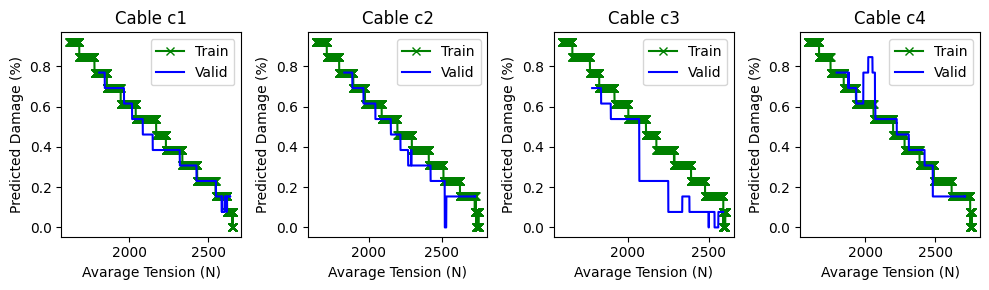

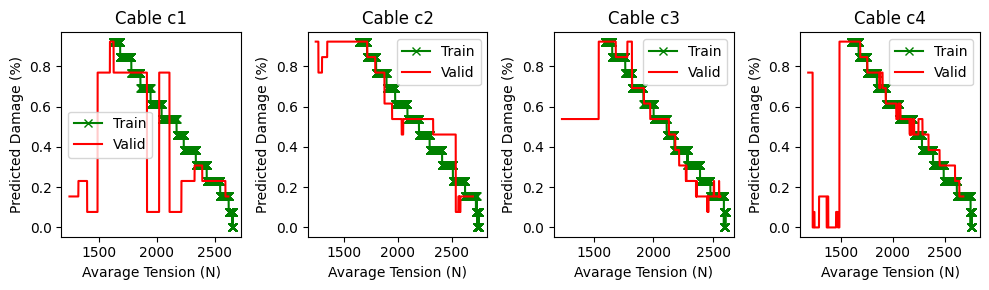

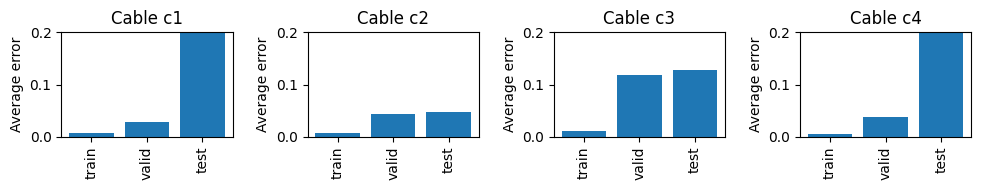

In [443]:
plt.figure(figsize=(10,3))
for i, cable in enumerate(dfs_train):
    plt.subplot(1,4,i+1)
    plt.title(f"Cable {cable}")
    plt.plot(tensions_train[cable], preds_train[cable], color="green", marker="x")
    plt.plot(tensions_valid[cable], preds_valid[cable], color="blue")
    plt.xlabel("Avarage Tension (N)")
    plt.ylabel("Predicted Damage (%)")
    plt.legend(["Train", "Valid"])
plt.tight_layout()

plt.figure(figsize=(10,3))
for i, cable in enumerate(dfs_train):
    plt.subplot(1,4,i+1)
    plt.title(f"Cable {cable}")
    plt.plot(tensions_train[cable], preds_train[cable], color="green", marker="x")
    plt.plot(tensions_test[cable], preds_test[cable], color="red")
    plt.xlabel("Avarage Tension (N)")
    plt.ylabel("Predicted Damage (%)")
    plt.legend(["Train", "Valid"])
plt.tight_layout()
    
plt.figure(figsize=(10,2))
for i, cable in enumerate(dfs_train):
    plt.subplot(1,4,i+1)
    plt.title(f"Cable {cable}")
    errors_train[cable]
    plt.bar(["train", "valid", "test"], [np.mean(errors_train[cable]), np.mean(errors_valid[cable]), np.mean(errors_test[cable])])
    plt.xticks(rotation=90);
    plt.ylabel("Average error")
    plt.ylim([0, 0.2])
plt.tight_layout()